In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

# Download the dataset
student_data = fetch_ucirepo(id=320)

# Combine features and target grades
df = pd.concat(
    [student_data.data.features, student_data.data.targets],
    axis=1
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display first five records
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (649, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-

In [5]:
# Check missing values in each column
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [8]:
print("Average First Period Grade:", df["G1"].mean())
print("Average Second Period Grade:", df["G2"].mean())
print("Average Final Grade:", df["G3"].mean())

Average First Period Grade: 11.399075500770415
Average Second Period Grade: 11.570107858243452
Average Final Grade: 11.906009244992296


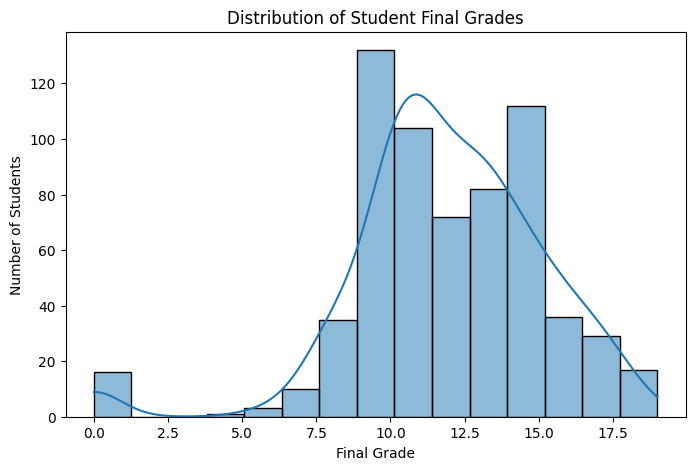

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

In [10]:
study_analysis = df.groupby("studytime")["G3"].mean()

print(study_analysis)

studytime
1    10.844340
2    12.091803
3    13.226804
4    13.057143
Name: G3, dtype: float64


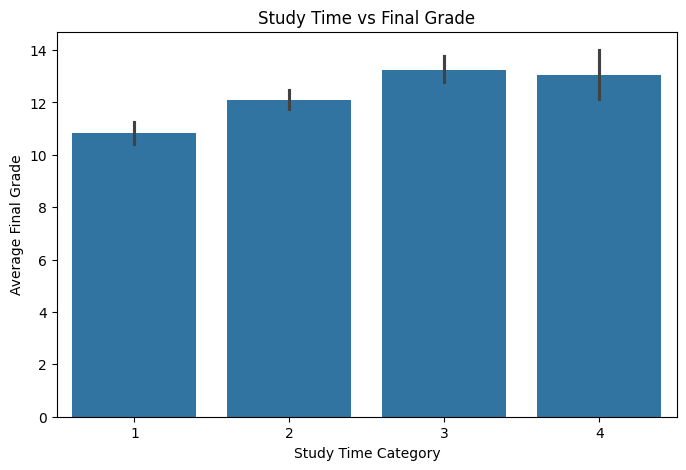

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()

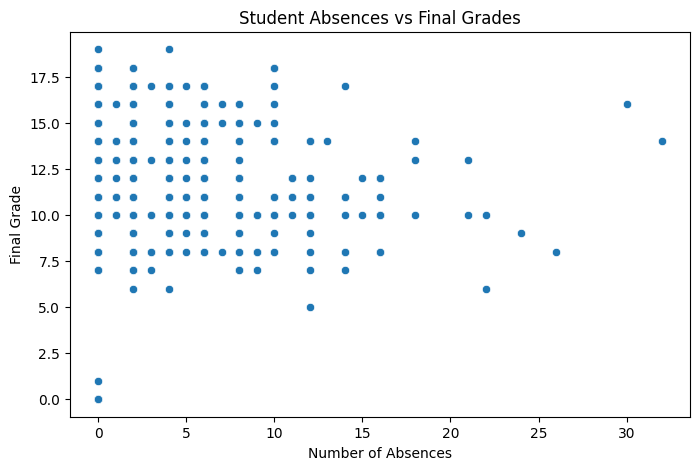

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

           studytime  absences        G1        G2        G3
studytime   1.000000 -0.118389  0.260875  0.240498  0.249789
absences   -0.118389  1.000000 -0.147149 -0.124745 -0.091379
G1          0.260875 -0.147149  1.000000  0.864982  0.826387
G2          0.240498 -0.124745  0.864982  1.000000  0.918548
G3          0.249789 -0.091379  0.826387  0.918548  1.000000


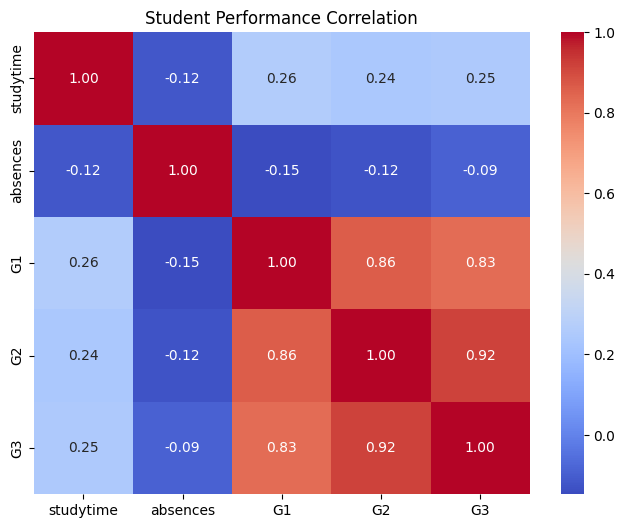

In [13]:
correlation = df[["studytime", "absences", "G1", "G2", "G3"]].corr()

print(correlation)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation")
plt.show()

In [14]:
print("Study time vs final grade:",
      df["studytime"].corr(df["G3"]))

print("Absences vs final grade:",
      df["absences"].corr(df["G3"]))

print("First grade vs final grade:",
      df["G1"].corr(df["G3"]))

Study time vs final grade: 0.24978868999886314
Absences vs final grade: -0.0913790564387561
First grade vs final grade: 0.8263871247890474


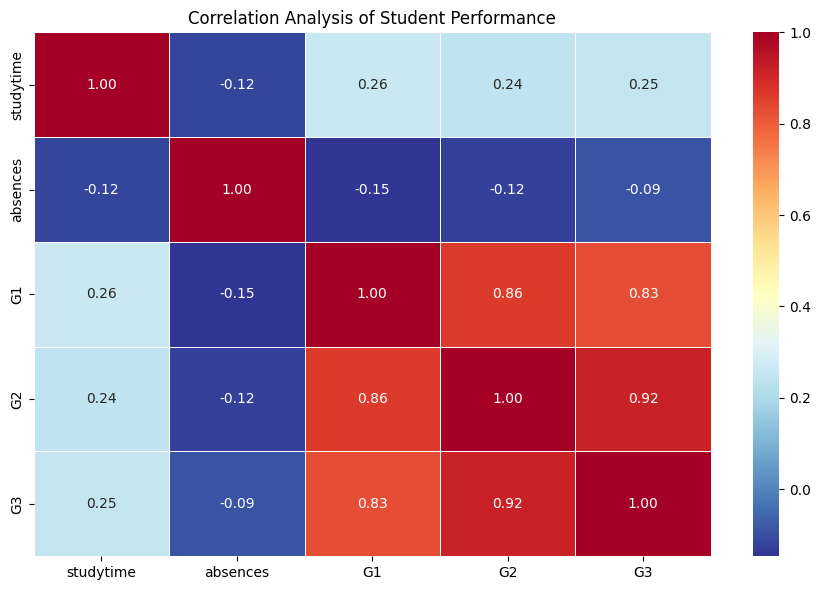

In [15]:
correlations = df[
    ["studytime", "absences", "G1", "G2", "G3"]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Analysis of Student Performance")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine Learning libraries imported!")

Machine Learning libraries imported!


In [17]:
# Input features
X = df[["studytime", "absences", "G1", "G2"]]

# Target variable
y = df["G3"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   studytime  absences  G1  G2
0          2         4   0  11
1          2         2   9  11
2          2         6  12  13
3          3         0  14  14
4          2         0  11  13

Target values:
0    11
1    11
2    12
3    14
4    13
Name: G3, dtype: int64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 519
Testing records: 130


In [19]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [20]:
predictions = model.predict(X_test)

print("Actual Grades:", list(y_test[:10]))
print("Predicted Grades:", predictions[:10])

Actual Grades: [19, 12, 18, 11, 11, 17, 18, 8, 10, 11]
Predicted Grades: [18.64651374 11.31471485 18.7380403  11.19906892 11.69072293 16.86674065
 17.67067398  9.56094122 10.44030349 10.48359131]


In [21]:
mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 0.7477392675349176
Mean Squared Error: 1.3720779659573386
R2 Score: 0.8592988178401069


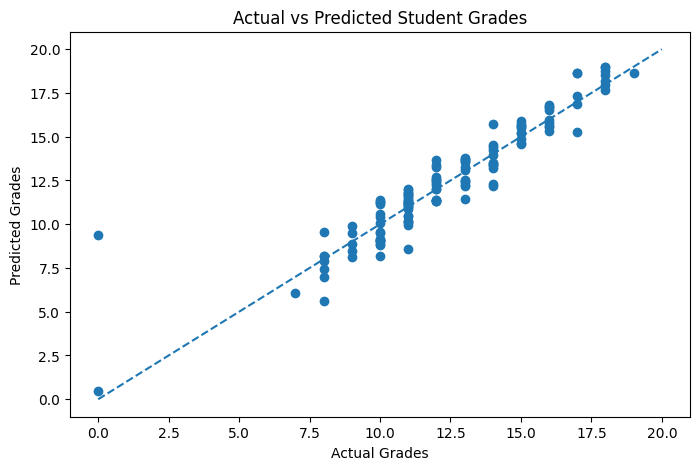

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted Student Grades")

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.show()

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Only study time and absences
X_A = df[["studytime", "absences"]]
y = df["G3"]

XA_train, XA_test, yA_train, yA_test = train_test_split(
    X_A, y, test_size=0.2, random_state=42
)

model_A = LinearRegression()
model_A.fit(XA_train, yA_train)

pred_A = model_A.predict(XA_test)

print("Model A - Study time and absences")
print("MAE:", mean_absolute_error(yA_test, pred_A))
print("MSE:", mean_squared_error(yA_test, pred_A))
print("R2:", r2_score(yA_test, pred_A))

Model A - Study time and absences
MAE: 2.30486003034338
MSE: 9.357258505668788
R2: 0.04045005736631069


In [24]:
X_B = df[["studytime", "absences", "G1", "G2"]]

XB_train, XB_test, yB_train, yB_test = train_test_split(
    X_B, y, test_size=0.2, random_state=42
)

model_B = LinearRegression()
model_B.fit(XB_train, yB_train)

pred_B = model_B.predict(XB_test)

print("Model B - All four features")
print("MAE:", mean_absolute_error(yB_test, pred_B))
print("MSE:", mean_squared_error(yB_test, pred_B))
print("R2:", r2_score(yB_test, pred_B))

Model B - All four features
MAE: 0.7477392675349176
MSE: 1.3720779659573386
R2: 0.8592988178401069


In [25]:
comparison = pd.DataFrame({
    "Model": ["Model A", "Model B"],
    "MAE": [
        mean_absolute_error(yA_test, pred_A),
        mean_absolute_error(yB_test, pred_B)
    ],
    "MSE": [
        mean_squared_error(yA_test, pred_A),
        mean_squared_error(yB_test, pred_B)
    ],
    "R2 Score": [
        r2_score(yA_test, pred_A),
        r2_score(yB_test, pred_B)
    ]
})

print(comparison)

     Model       MAE       MSE  R2 Score
0  Model A  2.304860  9.357259  0.040450
1  Model B  0.747739  1.372078  0.859299


In [26]:
importance = pd.DataFrame({
    "Feature": X_B.columns,
    "Coefficient": model_B.coef_
})

importance = importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(importance)

     Feature  Coefficient
3         G2     0.879362
2         G1     0.188004
0  studytime     0.118717
1   absences     0.024119


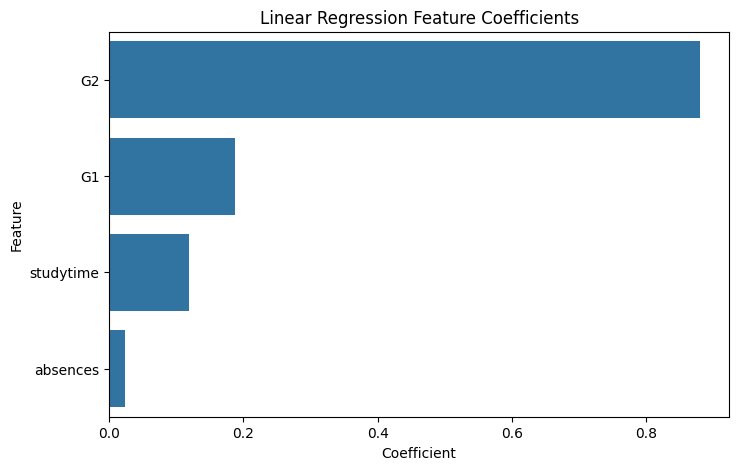

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [28]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

X = df[["studytime", "absences", "G1", "G2"]]
y = df["G3"]

model = LinearRegression()

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model, X, y,
    cv=cv,
    scoring="r2"
)

print("R² scores:", scores)
print("Average R²:", scores.mean())
print("Standard deviation:", scores.std())

R² scores: [0.85929882 0.855316   0.78473684 0.87666054 0.87148366]
Average R²: 0.8494991729554556
Standard deviation: 0.03330190843092364


In [30]:
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (649, 33)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    

In [31]:
print(student_data.metadata)

{'uci_id': 320, 'name': 'Student Performance', 'repository_url': 'https://archive.ics.uci.edu/dataset/320/student+performance', 'data_url': 'https://archive.ics.uci.edu/static/public/320/data.csv', 'abstract': 'Predict student performance in secondary education (high school). ', 'area': 'Social Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 649, 'num_features': 30, 'feature_types': ['Integer'], 'demographics': ['Sex', 'Age', 'Other', 'Education Level', 'Occupation'], 'target_col': ['G1', 'G2', 'G3'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Fri Jan 05 2024', 'dataset_doi': '10.24432/C5TG7T', 'creators': ['Paulo Cortez'], 'intro_paper': {'ID': 360, 'type': 'NATIVE', 'title': 'Using data mining to predict secondary school student performance', 'authors': 'P. Cortez, A. M. G. Silva', 'venue': 'Proceedings of 5th Annual Future Business Technolo

In [33]:
import pandas as pd
import requests
import zipfile
import io

# Correct UCI download URL
url = "https://archive.ics.uci.edu/static/public/320/student%2Bperformance.zip"

response = requests.get(url)
response.raise_for_status()

# Open outer ZIP
outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

print("Files found:", outer_zip.namelist())

# Extract inner ZIP if present
if "student.zip" in outer_zip.namelist():
    inner_zip = zipfile.ZipFile(
        io.BytesIO(outer_zip.read("student.zip"))
    )
else:
    inner_zip = outer_zip

# Load both subjects
math_df = pd.read_csv(
    inner_zip.open("student-mat.csv"), sep=";"
)

portuguese_df = pd.read_csv(
    inner_zip.open("student-por.csv"), sep=";"
)

# Add subject labels
math_df["subject"] = "Mathematics"
portuguese_df["subject"] = "Portuguese"

# Combine datasets
student_df = pd.concat(
    [math_df, portuguese_df],
    ignore_index=True
)

print("\nMathematics:", len(math_df))
print("Portuguese:", len(portuguese_df))
print("Combined:", len(student_df))

display(student_df.head())

Files found: ['.student.zip_old', 'student.zip']

Mathematics: 395
Portuguese: 649
Combined: 1044


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,Mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Mathematics


In [34]:
# Compare average grades by subject

subject_comparison = student_df.groupby("subject").agg({
    "G1": "mean",
    "G2": "mean",
    "G3": "mean",
    "absences": "mean",
    "studytime": "mean"
}).round(2)

print("Subject-wise Performance Comparison:")
display(subject_comparison)

Subject-wise Performance Comparison:


,G1,G2,G3,absences,studytime
subject,,,,,
Mathematics,10.91,10.71,10.42,5.71,2.04
Portuguese,11.40,11.57,11.91,3.66,1.93


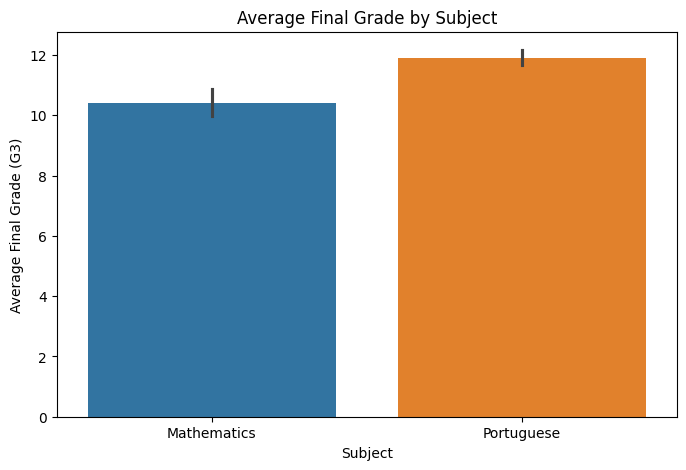

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=student_df,
    x="subject",
    y="G3",
    hue="subject",
    legend=False
)

plt.title("Average Final Grade by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Final Grade (G3)")
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.metrics import mean_squared_error

subjects = ["Mathematics", "Portuguese"]

results = []

features = ["studytime", "absences", "G1", "G2"]
target = "G3"

for subject in subjects:

    data = student_df[
        student_df["subject"] == subject
    ]

    X = data[features]
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Subject": subject,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions)
    })

comparison = pd.DataFrame(results)

print("Subject-wise Model Performance:")
display(comparison.round(4))

Subject-wise Model Performance:


,Subject,MAE,MSE,R2 Score
0,Mathematics,1.3126,4.1790,0.7962
1,Portuguese,0.7477,1.3721,0.8593


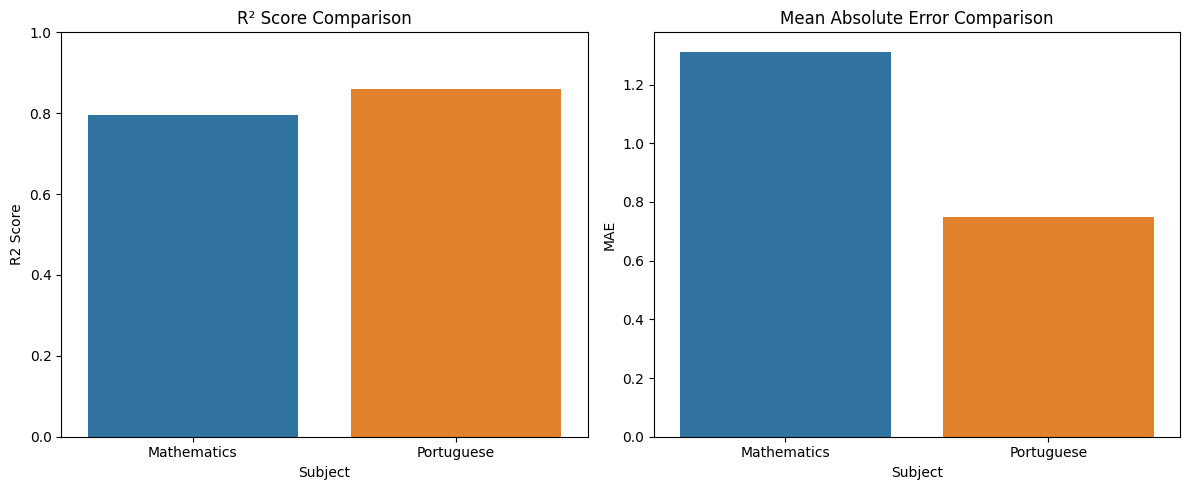

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare R2 scores
sns.barplot(
    data=comparison,
    x="Subject",
    y="R2 Score",
    hue="Subject",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("R² Score Comparison")
axes[0].set_ylim(0, 1)

# Compare MAE
sns.barplot(
    data=comparison,
    x="Subject",
    y="MAE",
    hue="Subject",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Mean Absolute Error Comparison")

plt.tight_layout()
plt.show()

In [38]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
import pandas as pd

features = ["studytime", "absences", "G1", "G2"]
target = "G3"

cv_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[features]
    y = data[target]

    model = LinearRegression()

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="r2"
    )

    cv_results.append({
        "Subject": subject,
        "Average R2": scores.mean(),
        "Standard Deviation": scores.std(),
        "Fold Scores": scores.round(4).tolist()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison)

,Subject,Average R2,Standard Deviation,Fold Scores
0,Mathematics,0.819193,0.031912,"[0.7962, 0.8228, 0.8549, 0.8506, 0.7714]"
1,Portuguese,0.849499,0.033302,"[0.8593, 0.8553, 0.7847, 0.8767, 0.8715]"



 Mathematics
Cross-validated MAE: 1.1852
Mean residual: -0.0038


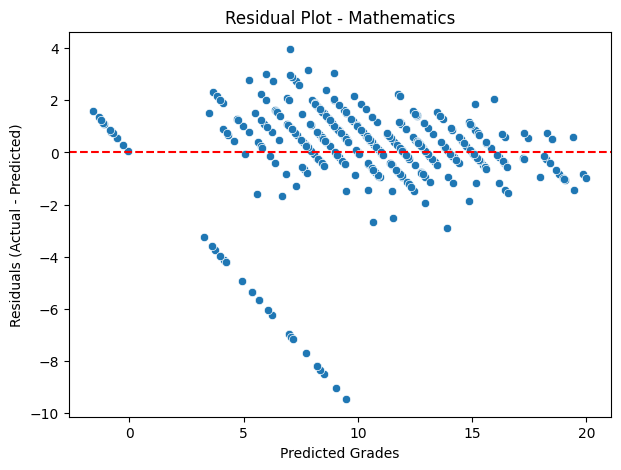


 Portuguese
Cross-validated MAE: 0.7935
Mean residual: -0.0081


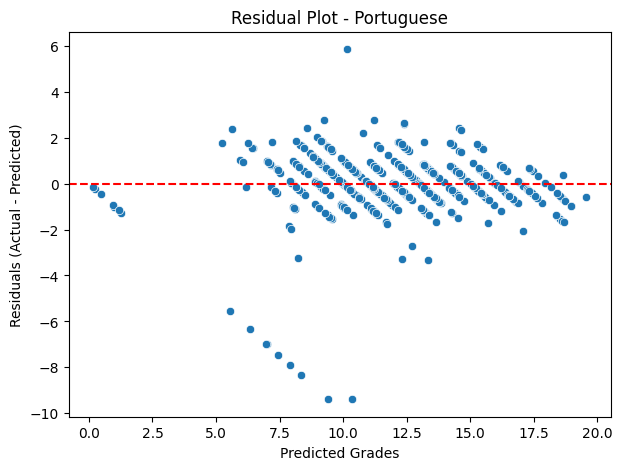

In [39]:
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

features = ["studytime", "absences", "G1", "G2"]

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[features]
    y = data["G3"]

    model = LinearRegression()

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    predictions = cross_val_predict(
        model, X, y, cv=kfold
    )

    residuals = y - predictions

    print("\n", subject)
    print("Cross-validated MAE:",
          round(mean_absolute_error(y, predictions), 4))
    print("Mean residual:",
          round(residuals.mean(), 4))

    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=predictions, y=residuals)

    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predicted Grades")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(f"Residual Plot - {subject}")
    plt.show()

In [40]:
early_features = [
    "studytime",
    "absences",
    "age",
    "failures",
    "schoolsup",
    "famsup",
    "internet",
    "higher"
]

print("Early prediction features:")
print(early_features)

print("\nNumber of features:", len(early_features))

Early prediction features:
['studytime', 'absences', 'age', 'failures', 'schoolsup', 'famsup', 'internet', 'higher']

Number of features: 8


In [41]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

numeric_features = [
    "studytime", "absences", "age", "failures"
]

categorical_features = [
    "schoolsup", "famsup", "internet", "higher"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

early_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[early_features]
    y = data["G3"]

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    predictions = cross_val_predict(
        model, X, y, cv=kfold
    )

    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)

    early_results.append({
        "Subject": subject,
        "Early Prediction MAE": round(mae, 4),
        "Early Prediction R2": round(r2, 4)
    })

display(pd.DataFrame(early_results))

,Subject,Early Prediction MAE,Early Prediction R2
0,Mathematics,3.3221,0.0927
1,Portuguese,2.0802,0.2300


In [42]:
late_results = [
    {"Subject": "Mathematics", "Late Prediction MAE": 1.1852,
     "Late Prediction R2": 0.8192},
    {"Subject": "Portuguese", "Late Prediction MAE": 0.7935,
     "Late Prediction R2": 0.8495}
]

late_df = pd.DataFrame(late_results)
early_df = pd.DataFrame(early_results)

final_comparison = pd.merge(
    early_df,
    late_df,
    on="Subject"
)

display(final_comparison.round(4))

,Subject,Early Prediction MAE,Early Prediction R2,Late Prediction MAE,Late Prediction R2
0,Mathematics,3.3221,0.0927,1.1852,0.8192
1,Portuguese,2.0802,0.2300,0.7935,0.8495


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import pandas as pd

importance_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]

    X = data[early_features]
    y = data["G3"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    model.fit(X_train, y_train)

    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42
    )

    subject_importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance.importances_mean
    }).sort_values("Importance", ascending=False)

    subject_importance["Subject"] = subject

    importance_results.append(subject_importance)

    print("\n", subject, "Feature Importance")
    display(subject_importance.round(4))


 Mathematics Feature Importance


,Feature,Importance,Subject
3,failures,0.2875,Mathematics
4,schoolsup,0.0491,Mathematics
2,age,0.0481,Mathematics
1,absences,-0.0238,Mathematics
0,studytime,-0.0424,Mathematics
7,higher,-0.0439,Mathematics
5,famsup,-0.0577,Mathematics
6,internet,-0.0628,Mathematics



 Portuguese Feature Importance


,Feature,Importance,Subject
3,failures,0.2195,Portuguese
7,higher,0.0891,Portuguese
0,studytime,0.0465,Portuguese
6,internet,0.0198,Portuguese
2,age,0.0050,Portuguese
5,famsup,0.0032,Portuguese
1,absences,0.0017,Portuguese
4,schoolsup,0.0016,Portuguese


In [45]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
import numpy as np

importance_cv_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]
    X = data[early_features]
    y = data["G3"]

    kfold = KFold(n_splits=5, shuffle=True, random_state=42)

    fold_importances = []

    for train_idx, test_idx in kfold.split(X):

        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", LinearRegression())
        ])

        model.fit(X_train, y_train)

        importance = permutation_importance(
            model,
            X_test,
            y_test,
            scoring="neg_mean_absolute_error",
            n_repeats=20,
            random_state=42
        )

        fold_importances.append(importance.importances_mean)

    mean_importance = np.mean(fold_importances, axis=0)
    std_importance = np.std(fold_importances, axis=0)

    result = pd.DataFrame({
        "Feature": early_features,
        "Mean Importance": mean_importance,
        "Std Deviation": std_importance,
        "Subject": subject
    }).sort_values("Mean Importance", ascending=False)

    importance_cv_results.append(result)

    print("\n", subject, "5-Fold Feature Importance")
    display(result.round(4))


 Mathematics 5-Fold Feature Importance


,Feature,Mean Importance,Std Deviation,Subject
3,failures,0.3133,0.1310,Mathematics
4,schoolsup,0.0825,0.0184,Mathematics
2,age,0.0752,0.0544,Mathematics
5,famsup,0.0270,0.0503,Mathematics
6,internet,0.0037,0.0333,Mathematics
1,absences,0.0006,0.0289,Mathematics
7,higher,-0.0147,0.0308,Mathematics
0,studytime,-0.0347,0.0552,Mathematics



 Portuguese 5-Fold Feature Importance


,Feature,Mean Importance,Std Deviation,Subject
3,failures,0.2267,0.0763,Portuguese
7,higher,0.1375,0.0741,Portuguese
0,studytime,0.0756,0.0340,Portuguese
4,schoolsup,0.0285,0.0259,Portuguese
6,internet,0.0245,0.0226,Portuguese
2,age,0.0064,0.0030,Portuguese
1,absences,0.0046,0.0037,Portuguese
5,famsup,-0.0019,0.0029,Portuguese


In [46]:
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

early_features = [
    "studytime", "absences", "age", "failures",
    "schoolsup", "famsup", "internet", "higher"
]

late_features = ["studytime", "absences", "G1", "G2"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

consistent_results = []

for subject in ["Mathematics", "Portuguese"]:

    data = student_df[student_df["subject"] == subject]
    y = data["G3"]

    for stage, features in [
        ("Early", early_features),
        ("Late", late_features)
    ]:

        X = data[features]

        if stage == "Early":
            preprocessor = ColumnTransformer([
                ("categorical",
                 OneHotEncoder(handle_unknown="ignore"),
                 ["schoolsup", "famsup", "internet", "higher"])
            ], remainder="passthrough")

            model = Pipeline([
                ("preprocessor", preprocessor),
                ("regressor", LinearRegression())
            ])
        else:
            model = LinearRegression()

        predictions = cross_val_predict(
            model, X, y, cv=cv
        )

        consistent_results.append({
            "Subject": subject,
            "Stage": stage,
            "MAE": mean_absolute_error(y, predictions),
            "R2": r2_score(y, predictions)
        })

consistent_comparison = pd.DataFrame(consistent_results)

display(consistent_comparison.round(4))

,Subject,Stage,MAE,R2
0,Mathematics,Early,3.3221,0.0927
1,Mathematics,Late,1.1852,0.8217
2,Portuguese,Early,2.0802,0.2300
3,Portuguese,Late,0.7935,0.8442
